Linear Graph Genrator 

In [4]:
import numpy as np
import math 
import matplotlib.pyplot as plt
import pandas as pd

row_start_end = [3,9] #Format: [starting row index in excel, ending row list in excel]
col_start_end = "R:T"   #Format: "starting col : ending col"   eg. "D:E"
file_name = "UDS_NewtonsRings"  #Excel file name, don't include .xlsx


#Need option to specify which values have errors



In [21]:
pd_file = pd.read_excel(file_name + ".xlsx", usecols= col_start_end)
just_data = pd_file.iloc[row_start_end[0]-2:row_start_end[1]-1]
val_lst = np.array(just_data.values.tolist())

x_val = val_lst[:,:1]
y_val = val_lst = []
print(x_val)

fig1 = plt.figure(1)

plt.show()


[[1.]
 [2.]
 [3.]
 [4.]
 [5.]
 [6.]
 [7.]]


<Figure size 640x480 with 0 Axes>

Error Calculator

Please plug in the variables and their error in val_err_lst. 
Then change f(ls) to the function desired

In [3]:
import numpy as np
import math 
import matplotlib.pyplot as plt
import pandas as pd

#Please put range of data for f(x)
row_start_end = [2,5] #Format: [starting row index in excel, ending row list in excel]
col_start_end = "H:I"   #Format: "starting col : ending col"   eg. "D:E"
file_name = "Coulomb's Law Working"  #Excel file name, don't include .xlsx
sheetnm = "Sheet7"

#Please write the f(x) 
def f(ls):      # fuction that calculates your desired value
    final_value = ((ls[3][0])**2)/(4*np.pi*((2*(ls[1][0])+(ls[2][0]))**2)*np.exp((ls[0][0])))
    return final_value
#(ls[0][0])

fx_name = r"{\epsilon_0}"
fx_units = r"n/a"


#### Extra Options! ####

##No excel sheet, manual data imput
use_excel = True  #Default: True
#val_err_lst = [[0.000210338,2.26561E-06],[5,0.2],[14.07640262,1.085922995]] #must also uncomment to use without excel


##Display component error tabel (Default: False)
display_component_tabel = True
if display_component_tabel:
    col_start_end = "M:O"  # If you want display the component tabel you need to change col_start_end to include the col with the names of the variables



##If you have an error that doesn't display in scientific notation you can change how many decimal places it will round to
non_sci_round = 10   # Default 10





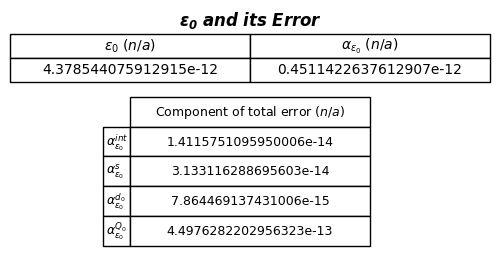

In [4]:
def flatten(matrix):
    flat_list = []
    for row in matrix:
        flat_list.extend(row)
    return flat_list

#Reading excel file
if use_excel and not(display_component_tabel):
    pd_file = pd.read_excel(file_name + ".xlsx",sheet_name=sheetnm, usecols= col_start_end)
    just_data = pd_file.iloc[row_start_end[0]-2:row_start_end[1]-1]
    val_err_lst = just_data.values.tolist()
elif use_excel and display_component_tabel:
    pd_file = pd.read_excel(file_name + ".xlsx",sheet_name= sheetnm, usecols= col_start_end)
    just_data = pd_file.iloc[row_start_end[0]-2:row_start_end[1]-1,1:]
    val_err_lst = just_data.values.tolist()
    var_names = flatten(pd_file.iloc[row_start_end[0]-2:row_start_end[1]-1,:1].values.tolist())
    

def copy2D(original, new):  #copies the first list and adds its values to the second 
    for i in range(len(original)):
        new += [original[i].copy()]

def sci_e_equal(num1,num2,round):
    e_1 = 10**(int(math.log10(num1))-1)
    if e_1 < 0.0001:
        e_1_s = "{0}".format(e_1)
        e_1_s = e_1_s[1:]
        prop_num2 = "{0}".format((num2 * e_1**-1))
        return prop_num2 + e_1_s
    else:
        e_2 = -1*(int(math.log10(num2))-round) 
        e_2_f = ':.{0}'.format(e_2)
        e_2_f = '{' + e_2_f + 'f}'
        return e_2_f.format(num2)



comp_err = [] #Will hold all the component errors to calculate the final error on the fuction
val_fin = f(val_err_lst) #Calculates the value of the fuction
err_fin = 0 

for i in range(len(val_err_lst)):
    adjusted_val = []
    copy2D(val_err_lst,adjusted_val) 
    adjusted_val[i][0] = val_err_lst[i][0] + val_err_lst[i][1]   #ajusted_val adds the error of a variable to that variable so current_err can be calculated
    curent_err = abs(f(adjusted_val) - val_fin)  #calculates the error due to a specific variable 
    comp_err += [curent_err]


tbl_comp_err = [] #for tabel of err components
comp_tbl_row = [] #for tabel of err components

for i in range(len(comp_err)):
    err_fin += (comp_err[i])**2
    tbl_comp_err += [[comp_err[i]]]
    if display_component_tabel:
        comp_tbl_row += ["$\\alpha_{0}^{{{1}}}$".format(fx_name,var_names[i])]  #Used when making the tabel for the error components

err_fin = np.sqrt(err_fin)



################################### Printing the tables #############################
fig = plt.figure(1) 
fig.add_axes((0,0,0.75,0.10))
ax = fig.gca()

# hide axes
ax.axis('off')
ax.axis('tight')
axtl = r"{0}\ and\ its\ Error".format(fx_name)
axtl = "$\\mathbfit{" + axtl + "}$"
ax.set_title(axtl)
#"${0}$ and its Error".format(fx_name), weight = 'bold'
fx_tbl_contents = [[val_fin,sci_e_equal(val_fin,err_fin,non_sci_round)]]
fx_tbl_headers = ["${0}$ (${1}$)".format(fx_name,fx_units), "$\\alpha_{0}$ (${1}$)".format(fx_name,fx_units)]


fx_tbl = ax.table(cellText=fx_tbl_contents,cellLoc="center",colWidths= [0.5,0.5],colLabels=fx_tbl_headers, loc='center') #Creates tabel for f(x) and its error
#setting the height of each cell
for c in fx_tbl.get_celld().values():
    c.set_height(0.5)


#### Code for error component tabel
if display_component_tabel:
    comp_tbl_headers = ["Component of total error (${0}$)".format(fx_units)]
    axis_height = 0.0578*len(comp_err) + 0.1424 #formula to calculate where to begin and the height of the axis based on the amount of component error

    fig.add_axes((0,-1*axis_height,0.75,axis_height))
    ax = fig.gca()
    ax.axis('off')
    ax.axis('tight')


    comp_tbl = ax.table(cellText=tbl_comp_err,cellLoc="center",colWidths=[0.5],colLabels=comp_tbl_headers,rowLabels=comp_tbl_row, loc='center')

    cell_height = 1/(2+len(comp_err))

    for c in comp_tbl.get_celld().values():
        c.set_height(cell_height)


plt.show()

The Bellow functions can be used to just calculate the value of a variable and its error, without any of the fancy graphing things.

In [5]:
import numpy as np
import math 
import matplotlib.pyplot as plt
import pandas as pd
import scipy.optimize as scpo


class UDS:
    def __init__(self,data_matrix):
        self.data = data_matrix

    @classmethod
    #The bellow function will save the data as a UDS object. The data will be in the form [[row1col1, row1col2,row1col3,...],[row2col1, row2col2, row2col3,...],...]
    def data_excel(cls, file, rows, colums, sheet_nm = "Sheet1"): #"file name",[1,3],"A:B"
        pd_file = pd.read_excel(file + ".xlsx",sheet_name=sheet_nm, usecols= colums)
        just_data = pd_file.iloc[rows[0]-2:rows[1]-1]
        fin_data = just_data.values.tolist()
        return cls(fin_data)
    
#Utility functions
    @staticmethod
    def flatten(matrix):
        flat_list = []
        for row in matrix:
            flat_list.extend(row)
        return flat_list
    @staticmethod
    def sci_e_equal(num1,num2,round = 10):
        e_1 = 10**(int(math.log10(num1))-1)
        if e_1 < 0.0001:
            e_1_s = "{0}".format(e_1)
            e_1_s = e_1_s[1:]
            prop_num2 = "{0}".format((num2 * e_1**-1))
            return prop_num2 + e_1_s
        else:
            e_2 = -1*(int(math.log10(num2))-round) 
            e_2_f = ':.{0}'.format(e_2)
            e_2_f = '{' + e_2_f + 'f}'
            return e_2_f.format(num2)

    def getData(self):  #Return data matrix
        return self.data

#Bellow are methods to calculate and display the error of a value using the functional aproach

    def functional_err(self, f, return_comp = False):
        comp_err = []
        orig_val = []
        for i in self.data:
            orig_val += [i[0]]
        fin_val = f(*orig_val)

        for i in range(len(self.data)):
            cur_val = orig_val.copy()
            cur_val[i] += self.data[i][1]
            comp_err += [abs(f(*cur_val) - fin_val)]

        fin_err = 0
        for i in comp_err:
            fin_err += i**2
        fin_err = (fin_err)**0.5
        
        if return_comp:
            return [[fin_val, fin_err], comp_err]
        return [fin_val, fin_err]
    
    def display_func_err(self, f, show_comp = False, **kwargs):
        fig = plt.figure(1) 
        fig.add_axes((0,0,0.75,0.10))
        ax = fig.gca()

        fx_name = "Z"
        fx_units = "n/a"
        comp_tbl_row = []  #The labels for the component table rows
        alphabet = ["A","B","C","D","E","F","G","H","I","J","K","L","M","N","O","P","Q","R","S","T","U","V","W","x","Y","Z"]

        if 'f_name' in kwargs:
            fx_name = kwargs['f_name']
        if 'f_units' in kwargs:
            fx_units = kwargs['f_units']

        if show_comp:
            all_data = self.functional_err(f,return_comp= True)
            val_fin = all_data[0][0]
            err_fin = all_data[0][1]
            comp_err = all_data[1].copy()
            tbl_comp_err = []  #Holds the actual values to display in the component err table
            var_names = alphabet[:len(self.data)]
            if 'var_names' in kwargs:
                var_names = kwargs['var_names']
            for i in range(len(comp_err)):
                tbl_comp_err += [[comp_err[i]]]
                comp_tbl_row += ["$\\alpha_{0}^{{{1}}}$".format(fx_name,var_names[i])]

        else:
            all_data = self.functional_err(f,return_comp= False)
            val_fin = all_data[0]
            err_fin = all_data[1]


        # hide axes
        ax.axis('off')
        ax.axis('tight')
        axtl = r"{0}\ and\ its\ Error".format(fx_name)
        axtl = "$\\mathbfit{" + axtl + "}$"
        ax.set_title(axtl)
        fx_tbl_contents = [[val_fin,UDS.sci_e_equal(val_fin,err_fin)]]
        fx_tbl_headers = ["${0}$ (${1}$)".format(fx_name,fx_units), "$\\alpha_{0}$ (${1}$)".format(fx_name,fx_units)]

        fx_tbl = ax.table(cellText=fx_tbl_contents,cellLoc="center",colWidths= [0.5,0.5],colLabels=fx_tbl_headers, loc='center') #Table creation
        #setting the height of each cell
        for c in fx_tbl.get_celld().values():
            c.set_height(0.5)


        #### Code for error component tabel
        if show_comp:
            comp_tbl_headers = ["Component of total error (${0}$)".format(fx_units)]
            axis_height = 0.0578*len(comp_err) + 0.1424 #formula to calculate where to begin and the height of the axis based on the amount of component error

            fig.add_axes((0,-1*axis_height,0.75,axis_height))
            ax = fig.gca()
            ax.axis('off')
            ax.axis('tight')


            comp_tbl = ax.table(cellText=tbl_comp_err,cellLoc="center",colWidths=[0.5],colLabels=comp_tbl_headers,rowLabels=comp_tbl_row, loc='center')

            cell_height = 1/(2+len(comp_err))

            for c in comp_tbl.get_celld().values():
                c.set_height(cell_height)
        plt.show()

    
             
            


##################### Test Zone ######################


